In [2]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

ML_DIR = Path(
    "/Users/harshitgoyal/Desktop/UCS503P/finshield_ai/code/ml"
)

SRC_DIR = ML_DIR / "src"
REPORT_DIR = ML_DIR / "reports" / "aml_shap"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

print("ML directory exists:", ML_DIR.exists())
print("Source directory exists:", SRC_DIR.exists())
print("SHAP version:", shap.__version__)

ML directory exists: True
Source directory exists: True
SHAP version: 0.46.0


In [5]:
from src.preprocessing_aml import normalize_transaction
from src.rules_aml import run_aml_rules
from src.behavior_aml import analyze_behavior
from src.network_aml import analyze_network
from src.scoring_aml import calculate_aml_score, risk_level
from src.analysis_aml import analyze_aml

print("Existing AML modules imported successfully.")

Existing AML modules imported successfully.


In [6]:
transaction = {
    "transaction_id": "TXN_DEMO_001",
    "timestamp": "2026/10/14 10:30",
    "sender_id": "BANK_A_ACCOUNT_101",
    "receiver_id": "BANK_B_ACCOUNT_202",
    "amount": 180000,
    "currency": "USD",
    "payment_format": "WIRE"
}

transaction_history = [
    {
        "transaction_id": "TXN_001",
        "timestamp": "2026/10/14 08:00",
        "sender_id": "BANK_A_ACCOUNT_101",
        "receiver_id": "BANK_B_ACCOUNT_202",
        "amount": 20000
    },
    {
        "transaction_id": "TXN_002",
        "timestamp": "2026/10/14 08:30",
        "sender_id": "BANK_A_ACCOUNT_101",
        "receiver_id": "BANK_C_ACCOUNT_303",
        "amount": 25000
    },
    {
        "transaction_id": "TXN_003",
        "timestamp": "2026/10/14 09:00",
        "sender_id": "BANK_D_ACCOUNT_404",
        "receiver_id": "BANK_A_ACCOUNT_101",
        "amount": 15000
    }
]

print("Transaction prepared.")
print(transaction)

Transaction prepared.
{'transaction_id': 'TXN_DEMO_001', 'timestamp': '2026/10/14 10:30', 'sender_id': 'BANK_A_ACCOUNT_101', 'receiver_id': 'BANK_B_ACCOUNT_202', 'amount': 180000, 'currency': 'USD', 'payment_format': 'WIRE'}


In [7]:
aml_result = analyze_aml(
    transaction,
    transaction_history
)

print("AML score:", aml_result["aml_score"])
print("Risk level:", aml_result["risk_level"])
print("Rule score:", aml_result["rule_score"])
print("Behavior score:", aml_result["behavior_score"])
print("Network score:", aml_result["network_score"])
print("Triggered rules:", aml_result["triggered_rules"])
print("Reasons:", aml_result["reasons"])

AML score: 0.5175
Risk level: MEDIUM
Rule score: 0.44999999999999996
Behavior score: 0.9
Network score: 0.0
Triggered rules: ['HIGH_AMOUNT', 'SUDDEN_ACTIVITY_SPIKE']
Reasons: ['Transaction amount is unusually high.', "Current transaction is much larger than the sender's historical average.", 'Transaction is at least five times the historical average.', 'No strong relationship anomaly was found in the supplied history.']


In [8]:
COMPONENT_NAMES = [
    "Rule score",
    "Behavior score",
    "Network score"
]

component_values = np.array([[
    aml_result["rule_score"],
    aml_result["behavior_score"],
    aml_result["network_score"]
]], dtype=float)

display(pd.DataFrame(
    component_values,
    columns=COMPONENT_NAMES
))

,Rule score,Behavior score,Network score
0,0.45,0.9,0.0


In [9]:
def final_aml_score_model(component_matrix):
    component_matrix = np.asarray(
        component_matrix,
        dtype=float
    )

    rule_score = component_matrix[:, 0]
    behavior_score = component_matrix[:, 1]
    network_score = component_matrix[:, 2]

    score = (
        0.45 * rule_score
        + 0.35 * behavior_score
        + 0.20 * network_score
    )

    return np.clip(score, 0.0, 1.0)

In [10]:
background = np.zeros((1, 3), dtype=float)

explainer = shap.KernelExplainer(
    final_aml_score_model,
    background,
    feature_names=COMPONENT_NAMES
)

shap_values = explainer.shap_values(
    component_values,
    nsamples=100
)

shap_values = np.asarray(shap_values).reshape(1, 3)

print("SHAP values generated successfully.")

display(pd.DataFrame({
    "Component": COMPONENT_NAMES,
    "Component score": component_values[0],
    "SHAP contribution": shap_values[0]
}))

  0%|          | 0/1 [00:00<?, ?it/s]

SHAP values generated successfully.


,Component,Component score,SHAP contribution
0,Rule score,0.45,0.2025
1,Behavior score,0.90,0.3150
2,Network score,0.00,0.0000


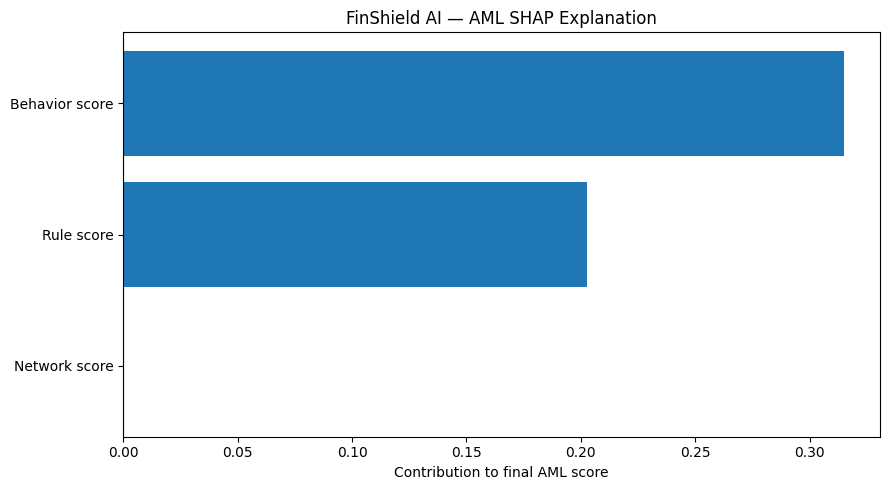

Plot saved to: /Users/harshitgoyal/Desktop/UCS503P/finshield_ai/code/ml/reports/aml_shap/aml_shap_components.png


In [11]:
contribution_df = pd.DataFrame({
    "Component": COMPONENT_NAMES,
    "SHAP contribution": shap_values[0]
}).sort_values("SHAP contribution")

plt.figure(figsize=(9, 5))

plt.barh(
    contribution_df["Component"],
    contribution_df["SHAP contribution"]
)

plt.xlabel("Contribution to final AML score")
plt.title("FinShield AI — AML SHAP Explanation")
plt.axvline(0, linewidth=0.8)
plt.tight_layout()

plot_path = REPORT_DIR / "aml_shap_components.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Plot saved to:", plot_path)

In [12]:
def generate_aml_shap_text(aml_result, shap_values):
    component_names = [
        "Rule score",
        "Behavior score",
        "Network score"
    ]

    contributions = np.asarray(
        shap_values
    ).reshape(-1)

    report = [
        "FINSHIELD AI - AML INVESTIGATION EXPLANATION",
        "=" * 52,
        f"AML score: {aml_result['aml_score']:.4f} / 1.0000",
        f"Risk level: {aml_result['risk_level']}",
        "",
        "SHAP component contributions:"
    ]

    ranked = sorted(
        zip(component_names, contributions),
        key=lambda item: abs(item[1]),
        reverse=True
    )

    for name, contribution in ranked:
        if contribution > 0:
            direction = "increased the AML score"
        elif contribution < 0:
            direction = "decreased the AML score"
        else:
            direction = "had no effect on the AML score"

        report.append(
            f"- {name}: {direction} "
            f"(SHAP contribution: {contribution:+.4f})"
        )

    report.extend([
        "",
        "Triggered rules:"
    ])

    triggered = aml_result.get("triggered_rules", [])

    if triggered:
        report.extend(f"- {rule}" for rule in triggered)
    else:
        report.append("- No configured rules were triggered.")

    report.extend([
        "",
        "Investigation reasons:"
    ])

    reasons = aml_result.get("reasons", [])

    if reasons:
        report.extend(f"- {reason}" for reason in reasons)
    else:
        report.append("- No additional reasons were returned.")

    report.extend([
        "",
        "Important:",
        "SHAP explains the contribution of the three score components.",
        "It does not independently establish that a transaction is laundering.",
        "The results require human investigation."
    ])

    return "\n".join(report)


text_report = generate_aml_shap_text(
    aml_result,
    shap_values
)

print(text_report)

FINSHIELD AI - AML INVESTIGATION EXPLANATION
AML score: 0.5175 / 1.0000
Risk level: MEDIUM

SHAP component contributions:
- Behavior score: increased the AML score (SHAP contribution: +0.3150)
- Rule score: increased the AML score (SHAP contribution: +0.2025)
- Network score: had no effect on the AML score (SHAP contribution: +0.0000)

Triggered rules:
- HIGH_AMOUNT
- SUDDEN_ACTIVITY_SPIKE

Investigation reasons:
- Transaction amount is unusually high.
- Current transaction is much larger than the sender's historical average.
- Transaction is at least five times the historical average.
- No strong relationship anomaly was found in the supplied history.

Important:
SHAP explains the contribution of the three score components.
It does not independently establish that a transaction is laundering.
The results require human investigation.


In [13]:
text_path = REPORT_DIR / "aml_shap_explanation.txt"

text_path.write_text(
    text_report,
    encoding="utf-8"
)

print("Text explanation saved to:", text_path)

Text explanation saved to: /Users/harshitgoyal/Desktop/UCS503P/finshield_ai/code/ml/reports/aml_shap/aml_shap_explanation.txt


In [14]:
json_report = {
    "aml_score": float(aml_result["aml_score"]),
    "risk_level": aml_result["risk_level"],
    "rule_score": float(aml_result["rule_score"]),
    "behavior_score": float(aml_result["behavior_score"]),
    "network_score": float(aml_result["network_score"]),
    "triggered_rules": aml_result.get("triggered_rules", []),
    "reasons": aml_result.get("reasons", []),
    "shap_contributions": {
        name: float(value)
        for name, value in zip(
            COMPONENT_NAMES,
            shap_values[0]
        )
    },
    "text_interpretation": text_report
}

json_path = REPORT_DIR / "aml_shap_explanation.json"

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(json_report, file, indent=2, default=str)

print("JSON report saved to:", json_path)

JSON report saved to: /Users/harshitgoyal/Desktop/UCS503P/finshield_ai/code/ml/reports/aml_shap/aml_shap_explanation.json


In [15]:
expected_score = float(
    final_aml_score_model(component_values)[0]
)

print("Existing AML score:", aml_result["aml_score"])
print("Score from SHAP scoring function:", round(expected_score, 4))

assert abs(
    expected_score - aml_result["aml_score"]
) < 0.00011, (
    "The scoring formula does not match scoring_aml.py. "
    "Check the component weights."
)

print("Verification passed.")

Existing AML score: 0.5175
Score from SHAP scoring function: 0.5175
Verification passed.
